# 01 · The Artificial Neuron

**Goal:** build a single neuron from scratch with NumPy, understand every activation function you will meet in modern AI (step, sigmoid, tanh, ReLU, Leaky ReLU, ELU, GELU, SiLU/Swish, softmax), and train one neuron with gradient descent.

**Contents**
1. From biology to math
2. A neuron in 10 lines of NumPy
3. Activation functions (and their derivatives)
4. Why non-linearity matters
5. Saturation, vanishing gradients and dead ReLUs
6. A neuron as a logic gate (and why XOR breaks it)
7. Training a neuron: the perceptron rule and gradient descent
8. Exercises

Everything here runs on a laptop CPU in a few seconds.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. From biology to math

A biological neuron receives signals through its **dendrites**, sums them in the **cell body**, and if the total exceeds a threshold it **fires** an electrical pulse down its **axon**.

The artificial neuron (McCulloch & Pitts 1943, Rosenblatt 1958) keeps only the essentials:

$$
z = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w}^\top \mathbf{x} + b \qquad\qquad a = f(z)
$$

| Symbol | Name | Role |
|---|---|---|
| $\mathbf{x}$ | inputs | the signals arriving at the neuron |
| $\mathbf{w}$ | weights | how much each input matters (learned) |
| $b$ | bias | shifts the threshold (learned) |
| $z$ | pre-activation / logit | the weighted sum |
| $f$ | activation function | decides the output shape (non-linear) |
| $a$ | activation / output | what the neuron "says" |

Geometrically, $\mathbf{w}^\top\mathbf{x} + b = 0$ is a **hyperplane** (a line in 2D). A single neuron splits its input space in two halves and the activation function decides how sharply.

## 2. A neuron in 10 lines of NumPy

In [2]:
class Neuron:
    def __init__(self, n_inputs, activation):
        self.w = np.random.randn(n_inputs) * 0.5   # small random weights
        self.b = 0.0
        self.activation = activation

    def forward(self, x):
        z = x @ self.w + self.b                   # weighted sum (works for one sample or a batch)
        return self.activation(z)

identity = lambda z: z
n = Neuron(3, identity)
x = np.array([1.0, 2.0, -1.0])
print("weights:", n.w.round(3), " bias:", n.b)
print("output :", n.forward(x).round(3))
print("check  :", (x * n.w).sum().round(3))

weights: [0.882 0.2   0.489]  bias: 0.0
output : 0.793
check  : 0.793


## 3. Activation functions

The activation function is what makes neural networks more powerful than linear regression. Below each one is implemented together with its **derivative**, because training (notebook 02) needs the derivative.

| Function | Formula | Range | Used in |
|---|---|---|---|
| Step (Heaviside) | $1$ if $z>0$ else $0$ | {0,1} | original perceptron; not differentiable |
| Sigmoid | $\sigma(z)=\frac{1}{1+e^{-z}}$ | (0,1) | binary outputs, LSTM gates |
| Tanh | $\tanh(z)$ | (-1,1) | RNNs, older MLPs |
| ReLU | $\max(0,z)$ | [0,∞) | default in CNNs and MLPs |
| Leaky ReLU | $\max(\alpha z, z)$ | (-∞,∞) | fixes "dead" ReLUs |
| ELU | $z$ if $z>0$ else $\alpha(e^z-1)$ | (-α,∞) | smooth negative side |
| GELU | $z\,\Phi(z)$ | ≈(-0.17,∞) | BERT, GPT-2/3, most transformers |
| SiLU / Swish | $z\,\sigma(z)$ | ≈(-0.28,∞) | LLaMA (inside SwiGLU), EfficientNet |
| Softmax | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ | probabilities | multi-class output layer, attention |

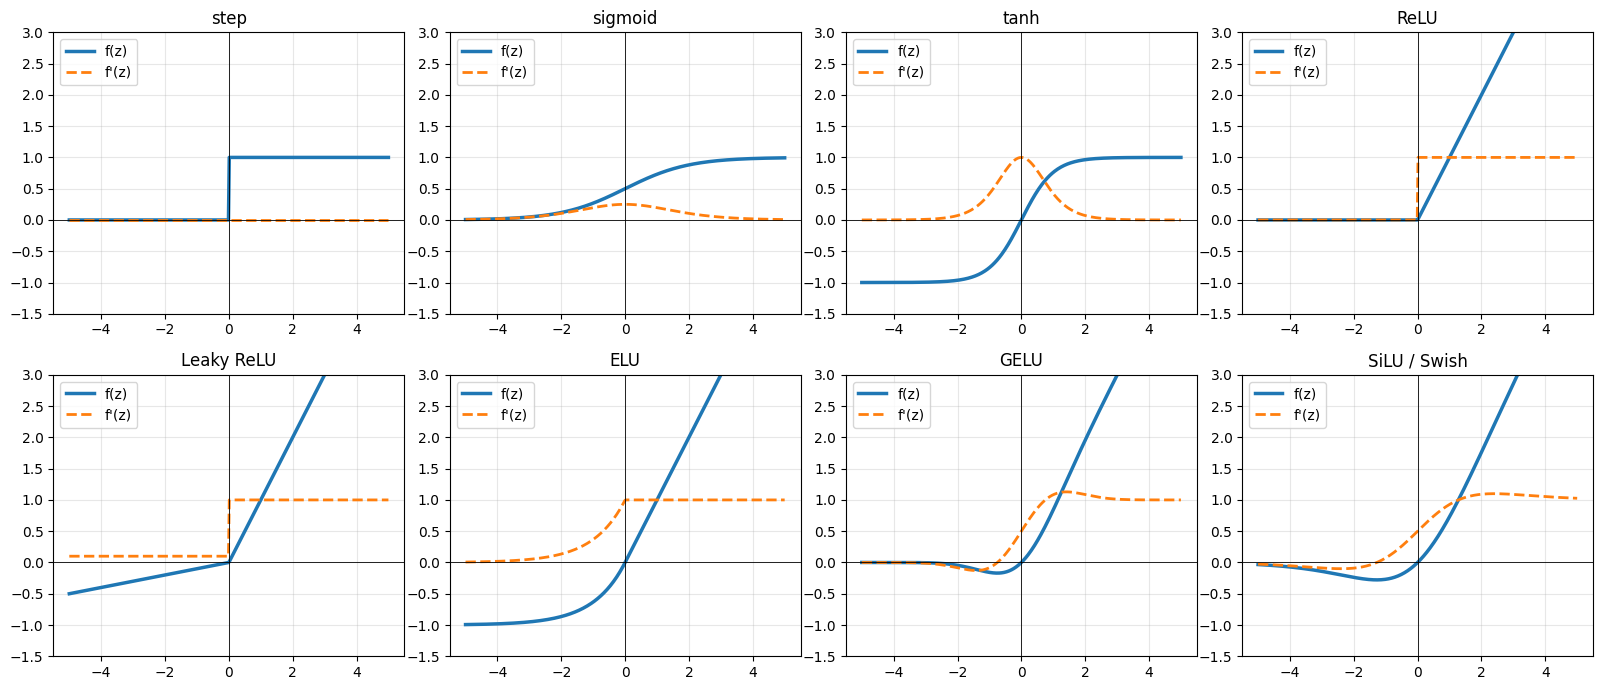

In [3]:
from math import erf, sqrt, pi
_erf = np.vectorize(erf)

def step(z):        return (z > 0).astype(float)
def d_step(z):      return np.zeros_like(z)               # zero everywhere (undefined at 0): useless for gradient descent

def sigmoid(z):     return 1 / (1 + np.exp(-z))
def d_sigmoid(z):   s = sigmoid(z); return s * (1 - s)

def tanh(z):        return np.tanh(z)
def d_tanh(z):      return 1 - np.tanh(z) ** 2

def relu(z):        return np.maximum(0, z)
def d_relu(z):      return (z > 0).astype(float)

def leaky_relu(z, a=0.1):   return np.where(z > 0, z, a * z)
def d_leaky_relu(z, a=0.1): return np.where(z > 0, 1.0, a)

def elu(z, a=1.0):   return np.where(z > 0, z, a * (np.exp(z) - 1))
def d_elu(z, a=1.0): return np.where(z > 0, 1.0, a * np.exp(z))

def gelu(z):        return 0.5 * z * (1 + _erf(z / sqrt(2)))   # exact: z * Phi(z)
def d_gelu(z):
    Phi = 0.5 * (1 + _erf(z / sqrt(2)))
    phi = np.exp(-z ** 2 / 2) / sqrt(2 * pi)
    return Phi + z * phi

def silu(z):        return z * sigmoid(z)
def d_silu(z):      s = sigmoid(z); return s + z * s * (1 - s)

ACTS = {
    "step": (step, d_step), "sigmoid": (sigmoid, d_sigmoid), "tanh": (tanh, d_tanh),
    "ReLU": (relu, d_relu), "Leaky ReLU": (leaky_relu, d_leaky_relu), "ELU": (elu, d_elu),
    "GELU": (gelu, d_gelu), "SiLU / Swish": (silu, d_silu),
}

z = np.linspace(-5, 5, 400)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (name, (f, df)) in zip(axes.ravel(), ACTS.items()):
    ax.plot(z, f(z), lw=2.5, label="f(z)")
    ax.plot(z, df(z), "--", lw=2, label="f'(z)")
    ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
    ax.set_title(name); ax.set_ylim(-1.5, 3); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

### Checking derivatives numerically

A good habit: whenever you write a derivative by hand, compare it with the **finite difference** $\frac{f(z+h)-f(z-h)}{2h}$. We will reuse this trick to verify backpropagation in notebook 02.

In [4]:
zs = np.linspace(-3, 3, 13) + 0.013     # avoid exactly 0 where ReLU-like kinks live
h = 1e-5
for name, (f, df) in ACTS.items():
    if name == "step":
        continue
    numeric = (f(zs + h) - f(zs - h)) / (2 * h)
    print(f"{name:13s} max |analytic - numeric| = {np.abs(numeric - df(zs)).max():.2e}")

sigmoid       max |analytic - numeric| = 7.95e-12
tanh          max |analytic - numeric| = 3.34e-11
ReLU          max |analytic - numeric| = 6.55e-12
Leaky ReLU    max |analytic - numeric| = 6.55e-12
ELU           max |analytic - numeric| = 1.09e-11
GELU          max |analytic - numeric| = 1.65e-11
SiLU / Swish  max |analytic - numeric| = 1.35e-11


### Softmax: an activation for a *layer*, not a single neuron

Softmax turns a vector of scores (logits) into a probability distribution. It is used at the output of classifiers and, crucially, **inside attention** (notebook 07). Two practical details:

* **Numerical stability:** subtract $\max(z)$ before exponentiating. The result is identical but no overflow.
* **Temperature $T$:** $\text{softmax}(z/T)$. Small $T$ → peaky (confident), large $T$ → flat (uncertain). This is exactly the "temperature" knob of ChatGPT-like models (notebook 08).

naive exp on huge logits overflows: [inf]
stable softmax on huge logits     : [0.7311 0.2689]


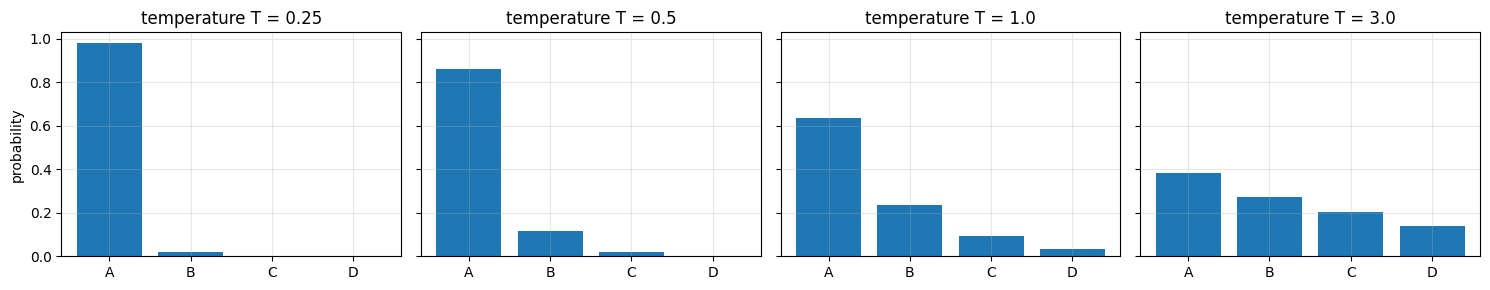

In [5]:
def softmax(z, T=1.0):
    z = np.asarray(z, dtype=float) / T
    z = z - z.max(axis=-1, keepdims=True)           # stability trick
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

logits = np.array([2.0, 1.0, 0.1, -1.0])
print("naive exp on huge logits overflows:", np.exp(np.array([1000.0])))
print("stable softmax on huge logits     :", softmax([1000.0, 999.0]).round(4))

fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, T in zip(axes, [0.25, 0.5, 1.0, 3.0]):
    ax.bar(["A", "B", "C", "D"], softmax(logits, T), color="tab:blue")
    ax.set_title(f"temperature T = {T}")
axes[0].set_ylabel("probability"); plt.tight_layout(); plt.show()

## 4. Why non-linearity matters

If $f$ is the identity, stacking layers buys nothing: $W_2(W_1 x + b_1) + b_2 = (W_2W_1)x + (W_2 b_1 + b_2)$ is **still one linear map**. A 100-layer linear network is exactly as expressive as a single layer.

With a non-linearity in between, a network can bend space. The cell below verifies both statements numerically.

two linear layers == one linear layer: True


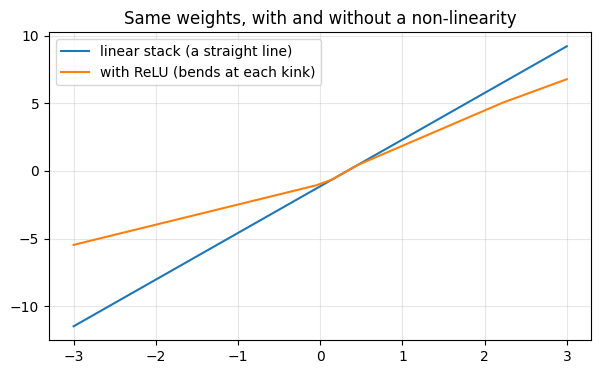

In [6]:
W1, b1 = np.random.randn(5, 2), np.random.randn(5)
W2, b2 = np.random.randn(1, 5), np.random.randn(1)

X = np.random.randn(100, 2)
deep_linear = (X @ W1.T + b1) @ W2.T + b2
W, b = W2 @ W1, W2 @ b1 + b2                          # collapse into one layer
print("two linear layers == one linear layer:", np.allclose(deep_linear, X @ W.T + b))

# With ReLU in between, the function is piecewise linear: it can bend.
x1 = np.linspace(-3, 3, 300)
grid = np.stack([x1, np.zeros_like(x1)], axis=1)
plt.plot(x1, ((grid @ W1.T + b1) @ W2.T + b2).ravel(), label="linear stack (a straight line)")
plt.plot(x1, (relu(grid @ W1.T + b1) @ W2.T + b2).ravel(), label="with ReLU (bends at each kink)")
plt.legend(); plt.title("Same weights, with and without a non-linearity"); plt.show()

## 5. Saturation, vanishing gradients and dead ReLUs

During training, gradients are multiplied by $f'(z)$ at every layer (notebook 02 shows why). This makes the derivative plots above very important:

* **Sigmoid:** $\sigma'(z) \le 0.25$. Ten sigmoid layers multiply the gradient by at most $0.25^{10} \approx 10^{-6}$. The early layers stop learning: the **vanishing gradient problem**. For large $|z|$ the neuron is **saturated** and its gradient is almost exactly 0.
* **Tanh:** derivative up to 1 and zero-centred, better, but still saturates.
* **ReLU:** derivative exactly 1 for $z>0$: gradients pass unchanged. This is the main reason deep learning took off around 2012. Downside: if $z<0$ for every input, the derivative is 0 forever and the neuron is **dead**.
* **Leaky ReLU / ELU / GELU / SiLU:** keep a small non-zero gradient for negative inputs, so neurons can recover.

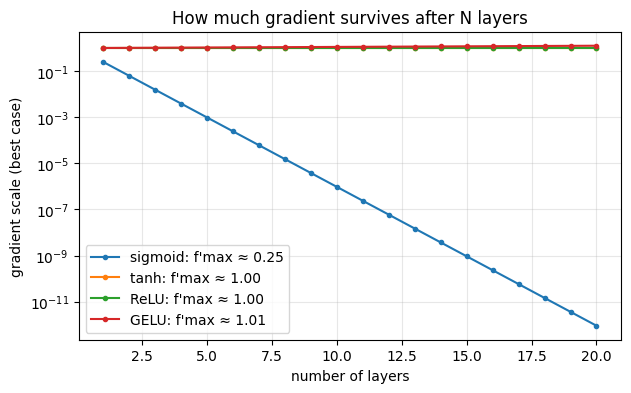

fraction of inputs where the dead neuron fires: 0.0
its gradient w.r.t. z is therefore always     : 0.0


In [7]:
depths = np.arange(1, 21)
for name in ["sigmoid", "tanh", "ReLU", "GELU"]:
    f, df = ACTS[name]
    best_case = df(np.array([0.0 if name in ("sigmoid", "tanh") else 3.0]))[0]
    plt.semilogy(depths, best_case ** depths, marker="o", ms=3, label=f"{name}: f'max ≈ {best_case:.2f}")
plt.xlabel("number of layers"); plt.ylabel("gradient scale (best case)")
plt.title("How much gradient survives after N layers"); plt.legend(); plt.show()

# Dead ReLU demo: a neuron with a very negative bias never activates.
dead = Neuron(2, relu); dead.b = -10.0
X = np.random.randn(1000, 2)
print("fraction of inputs where the dead neuron fires:", (dead.forward(X) > 0).mean())
print("its gradient w.r.t. z is therefore always     :", d_relu(X @ dead.w + dead.b).max())

## 6. A neuron as a logic gate

With a step activation, choosing weights by hand gives the classic logic gates. AND fires only if both inputs are 1; OR fires if at least one is.

**XOR** (exactly one input is 1) is impossible: there is no single straight line separating $\{(0,1),(1,0)\}$ from $\{(0,0),(1,1)\}$. Minsky & Papert pointed this out in 1969 and it contributed to the first "AI winter". The fix is a **network** of neurons, which notebook 02 builds and trains.

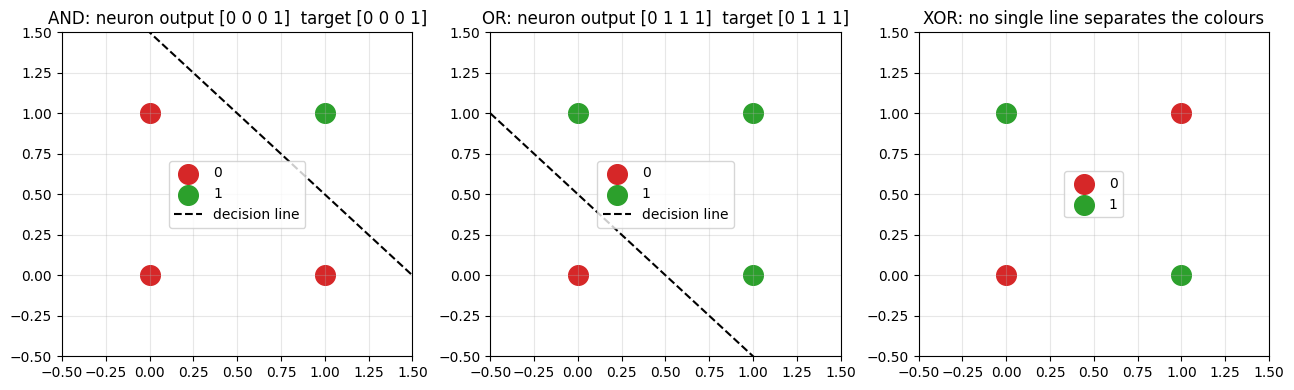

In [8]:
X_bool = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
gates = {"AND": (np.array([1.0, 1.0]), -1.5), "OR": (np.array([1.0, 1.0]), -0.5)}
targets = {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "XOR": [0, 1, 1, 0]}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes, ["AND", "OR", "XOR"]):
    y = np.array(targets[name])
    ax.scatter(*X_bool[y == 0].T, s=200, c="tab:red", label="0")
    ax.scatter(*X_bool[y == 1].T, s=200, c="tab:green", label="1")
    if name in gates:
        w, b = gates[name]
        out = step(X_bool @ w + b)
        xs = np.linspace(-0.5, 1.5, 10)
        ax.plot(xs, -(w[0] * xs + b) / w[1], "k--", label="decision line")
        ax.set_title(f"{name}: neuron output {out.astype(int)}  target {y}")
    else:
        ax.set_title("XOR: no single line separates the colours")
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5); ax.legend(loc="center")
plt.tight_layout(); plt.show()

## 7. Training a neuron

Choosing weights by hand does not scale. We want the neuron to **learn** them from examples.

### 7a. The perceptron learning rule (Rosenblatt, 1958)

For every misclassified example, nudge the weights towards it:
$$\mathbf{w} \leftarrow \mathbf{w} + \eta\,(y - \hat y)\,\mathbf{x}, \qquad b \leftarrow b + \eta\,(y-\hat y)$$
It is guaranteed to converge **if** the data is linearly separable.

misclassifications per epoch: [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


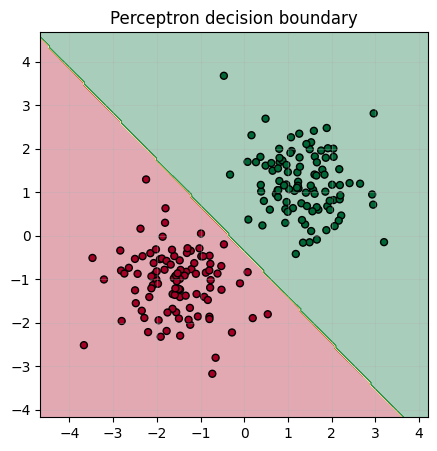

In [9]:
def make_blobs(n=200, seed=1):
    rng = np.random.default_rng(seed)
    a = rng.normal([-1.5, -1.0], 0.8, size=(n // 2, 2))
    b = rng.normal([1.5, 1.2], 0.8, size=(n // 2, 2))
    return np.vstack([a, b]), np.array([0] * (n // 2) + [1] * (n // 2))

X, y = make_blobs()
w, b, eta = np.zeros(2), 0.0, 0.1
errors_per_epoch = []
for epoch in range(20):
    errors = 0
    for xi, yi in zip(X, y):
        y_hat = step(np.array(xi @ w + b))
        if y_hat != yi:
            w += eta * (yi - y_hat) * xi
            b += eta * (yi - y_hat)
            errors += 1
    errors_per_epoch.append(errors)
print("misclassifications per epoch:", errors_per_epoch)

def plot_boundary(ax, predict, X, y, title):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200))
    P = predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, P, levels=20, cmap="RdYlGn", alpha=0.35)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdYlGn", edgecolors="k", s=25)
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(5, 5))
plot_boundary(ax, lambda P: step(P @ w + b), X, y, "Perceptron decision boundary")
plt.show()

### 7b. Gradient descent with a sigmoid neuron (= logistic regression)

The step function has zero derivative, so we cannot ask "in which direction should each weight move to reduce the error?". Swap it for the smooth **sigmoid**, interpret the output as a probability $\hat y = \sigma(z)$, and minimise the **binary cross-entropy** loss:

$$ L = -\frac{1}{N}\sum_i \big[y_i \log \hat y_i + (1-y_i)\log(1-\hat y_i)\big] $$

The chain rule gives a beautifully simple gradient (the sigmoid derivative cancels the log):

$$ \frac{\partial L}{\partial z_i} = \frac{\hat y_i - y_i}{N}, \qquad \frac{\partial L}{\partial \mathbf{w}} = X^\top \frac{\hat{\mathbf{y}} - \mathbf{y}}{N}, \qquad \frac{\partial L}{\partial b} = \text{mean}(\hat{\mathbf{y}} - \mathbf{y}) $$

Then repeat: $\mathbf{w} \leftarrow \mathbf{w} - \eta \nabla_\mathbf{w} L$. This loop **is** the whole idea of training, and every model up to GPT-scale uses it.

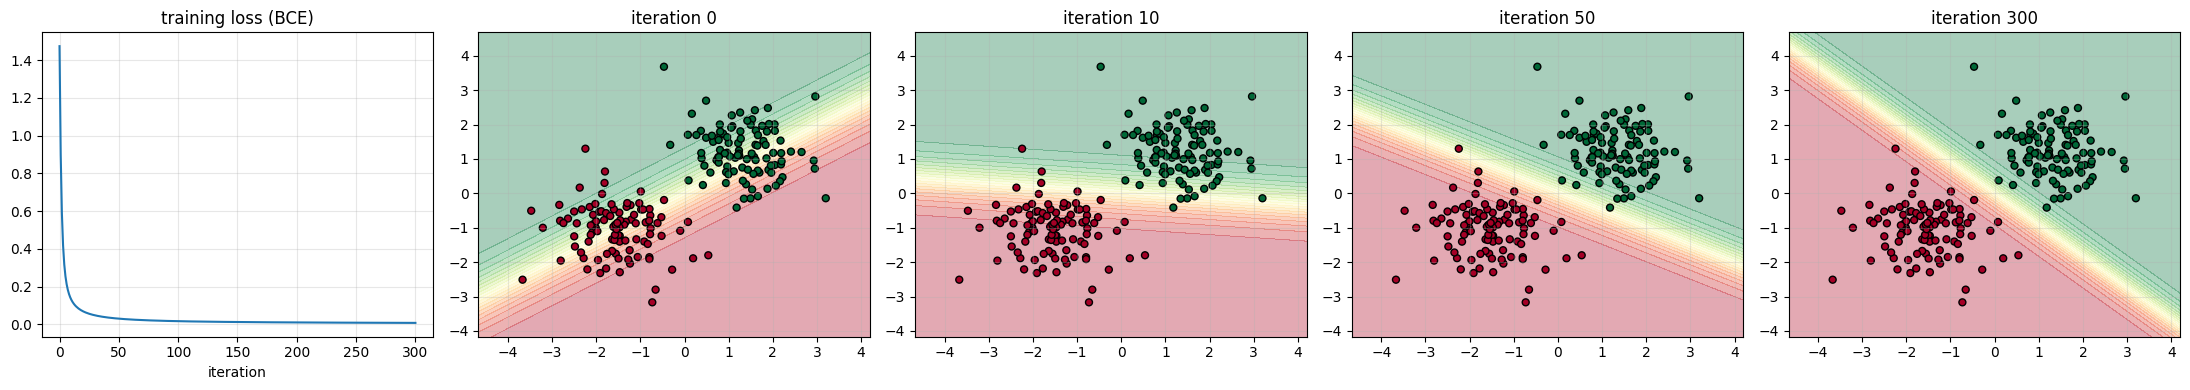

final loss 0.007, accuracy 100.0%, w=[2.89 3.16], b=-0.05


In [10]:
def bce(y_hat, y, eps=1e-12):
    y_hat = np.clip(y_hat, eps, 1 - eps)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

neuron = Neuron(2, sigmoid)
neuron.w = np.array([-2.0, 2.0])         # deliberately bad start so we can watch it learn
eta, history, snapshots = 0.5, [], {}
for it in range(301):
    y_hat = neuron.forward(X)
    history.append(bce(y_hat, y))
    grad_z = (y_hat - y) / len(y)
    neuron.w -= eta * (X.T @ grad_z)
    neuron.b -= eta * grad_z.sum()
    if it in (0, 10, 50, 300):
        snapshots[it] = (neuron.w.copy(), neuron.b)

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
axes[0].plot(history); axes[0].set_title("training loss (BCE)"); axes[0].set_xlabel("iteration")
for ax, (it, (w_s, b_s)) in zip(axes[1:], snapshots.items()):
    plot_boundary(ax, lambda P: sigmoid(P @ w_s + b_s), X, y, f"iteration {it}")
plt.tight_layout(); plt.show()
acc = ((neuron.forward(X) > 0.5) == y).mean()
print(f"final loss {history[-1]:.3f}, accuracy {acc:.1%}, w={neuron.w.round(2)}, b={neuron.b:.2f}")

### Same neuron, same result, in PyTorch

Frameworks like PyTorch compute the gradients for us (**automatic differentiation**). Notebook 02 opens that black box.

In [11]:
import torch
torch.manual_seed(0)
Xt, yt = torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)
layer = torch.nn.Linear(2, 1)                        # w and b
opt = torch.optim.SGD(layer.parameters(), lr=0.5)
for it in range(300):
    loss = torch.nn.functional.binary_cross_entropy_with_logits(layer(Xt).squeeze(1), yt)
    opt.zero_grad(); loss.backward(); opt.step()
print(f"PyTorch loss {loss.item():.3f}, accuracy {((layer(Xt).squeeze(1) > 0).float() == yt).float().mean():.1%}")

PyTorch loss 0.008, accuracy 100.0%


## Key takeaways

* A neuron is a **weighted sum + bias + non-linear activation**. It draws one hyperplane.
* Activations are chosen for their **gradient behaviour**: ReLU-family functions keep gradients alive; sigmoid/tanh saturate. Modern transformers use **GELU** or **SiLU** (smooth ReLU variants).
* **Softmax** turns scores into probabilities; temperature controls how sharp they are.
* Training = define a loss, compute its gradient with the chain rule, step downhill. Repeat.
* One neuron cannot solve XOR. We need **layers**, which is the topic of **notebook 02**.

## Exercises

1. Train the sigmoid neuron with `eta = 5.0` and `eta = 0.01`. What happens to the loss curve?
2. Replace `sigmoid` with `tanh` in section 7b (map labels to −1/+1 and use MSE). Does it converge faster?
3. Find weights by hand for a NAND gate. Why is NAND called "universal"?
4. Implement the **Mish** activation $z\tanh(\ln(1+e^z))$ and its derivative; verify with finite differences.
5. Generate blobs that overlap heavily. What happens to the perceptron rule? And to gradient descent?